In [4]:
!pip install pandas numpy scikit-learn matplotlib seaborn pgmpy openpyxl


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np

# Load local files
df_heart = pd.read_csv('heart_rate_data (1).csv')
df_handover = pd.read_csv('handover_ready_dataset.csv')
df_emo = pd.read_excel('emotional_monitoring_ready.xlsx')

# Load SWELL dataset (adjust file path if using Kaggle CSV)
# df_swell = pd.read_csv('swell_hrv_dataset.csv')

print("Heart Rate Data Shape:", df_heart.shape)
print("Handover Dataset Shape:", df_handover.shape)
print("Emotional Monitoring Shape:", df_emo.shape)

print("\nHandover State Classes:\n", df_handover['State'].value_counts())
print("\nEmotional State Classes:\n", df_emo['EmotionalState'].value_counts())

Heart Rate Data Shape: (500, 6)
Handover Dataset Shape: (76, 12)
Emotional Monitoring Shape: (1000, 11)

Handover State Classes:
 State
Normal    28
Alert     26
Danger    22
Name: count, dtype: int64

Emotional State Classes:
 EmotionalState
partially engaged    347
engaged              332
disengaged           321
Name: count, dtype: int64


In [6]:
from sklearn.preprocessing import MinMaxScaler

# 1. Standardize Handover Dataset Target Labels
# Mapping text states to unified stress levels (0: Low, 1: Moderate, 2: High)
state_mapping_handover = {
    'Normal': 0,
    'Low': 0,
    'Moderate': 1,
    'High': 2,
    'Extreme': 2
}
df_handover['Stress_Level'] = df_handover['State'].map(state_mapping_handover).fillna(0).astype(int)

# 2. Standardize Emotional Monitoring Target Labels
state_mapping_emo = {
    'relaxed': 0,
    'engaged': 1,
    'distracted': 1,
    'stressed': 2,
    'anxious': 2
}
df_emo['Stress_Level'] = df_emo['EmotionalState'].map(state_mapping_emo).fillna(1).astype(int)

# 3. Rename common feature columns for alignment
df_handover_clean = df_handover.rename(columns={
    'HR_mean': 'HeartRate',
    'Body_Temp': 'Temperature',
    'EEG_Stress_Index': 'EEG_Index'
})

df_emo_clean = df_emo.rename(columns={
    'EEG': 'EEG_Index'
})

# Align on common numerical features present across datasets
common_features = ['HeartRate', 'Temperature', 'EEG_Index']

X_handover = df_handover_clean[common_features]
y_handover = df_handover_clean['Stress_Level']

X_emo = df_emo_clean[common_features]
y_emo = df_emo_clean['Stress_Level']

# Combine aligned subsets into a single dataset
X_combined = pd.concat([X_handover, X_emo], axis=0).reset_index(drop=True)
y_combined = pd.concat([y_handover, y_emo], axis=0).reset_index(drop=True)

# Normalize numerical features using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_combined), columns=common_features)

print("Combined Features Shape:", X_scaled.shape)
print("Combined Target Class Distribution:\n", y_combined.value_counts())

Combined Features Shape: (1076, 3)
Combined Target Class Distribution:
 Stress_Level
1    1000
0      76
Name: count, dtype: int64


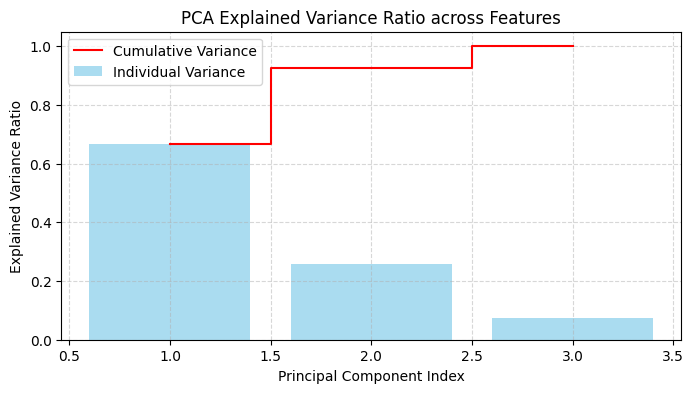


PCA Component Loadings:
     HeartRate  Temperature  EEG_Index
PC1   0.667808     0.474575  -0.573420
PC2  -0.167220     0.846343   0.505708
PC3   0.725306    -0.241828   0.644554


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Fit PCA
pca = PCA(n_components=len(common_features))
X_pca = pca.fit_transform(X_scaled)

# Plot Explained Variance Ratio (Scree Plot)
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, alpha=0.7, color='skyblue', label='Individual Variance')
plt.step(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), where='mid', color='red', label='Cumulative Variance')
plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA Explained Variance Ratio across Features')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Display feature weights in PC1 and PC2
components_df = pd.DataFrame(pca.components_, columns=common_features, index=[f'PC{i+1}' for i in range(len(common_features))])
print("\nPCA Component Loadings:")
print(components_df)

In [8]:
# Create a discretized dataframe for Bayesian Network modeling
df_bbn = pd.DataFrame()

for col in common_features:
    df_bbn[col] = pd.qcut(X_scaled[col], q=3, labels=['Low', 'Medium', 'High'], duplicates='drop')

df_bbn['Stress_Level'] = y_combined.map({0: 'Low', 1: 'Medium', 2: 'High'})

print("Discretized Dataset Sample:")
print(df_bbn.head())

Discretized Dataset Sample:
  HeartRate Temperature EEG_Index Stress_Level
0       Low         Low       Low          Low
1       Low         Low       Low          Low
2       Low         Low       Low          Low
3       Low         Low       Low          Low
4       Low         Low       Low          Low


In [14]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

# 1. Instantiate Discrete Bayesian Network
model = DiscreteBayesianNetwork([
    ('HeartRate', 'Stress_Level'),
    ('Temperature', 'Stress_Level'),
    ('EEG_Index', 'Stress_Level')
])

# 2. Fit model directly (uses default MLE automatically)
model.fit(df_bbn)

# 3. Print learned CPT for Stress_Level
print("Learned CPT for Stress_Level:")
print(model.get_cpds('Stress_Level'))

# 4. Check model validity
print("\nIs model structure valid?", model.check_model())

Learned CPT for Stress_Level:
+----------------------+-----+---------------------+
| EEG_Index            | ... | EEG_Index(Medium)   |
+----------------------+-----+---------------------+
| HeartRate            | ... | HeartRate(Medium)   |
+----------------------+-----+---------------------+
| Temperature          | ... | Temperature(Medium) |
+----------------------+-----+---------------------+
| Stress_Level(Low)    | ... | 0.0                 |
+----------------------+-----+---------------------+
| Stress_Level(Medium) | ... | 1.0                 |
+----------------------+-----+---------------------+

Is model structure valid? True


--- Bayesian Belief Network Performance ---
              precision    recall  f1-score   support

         Low       1.00      0.88      0.94        17
      Medium       0.99      1.00      0.99       183

    accuracy                           0.99       200
   macro avg       0.99      0.94      0.97       200
weighted avg       0.99      0.99      0.99       200



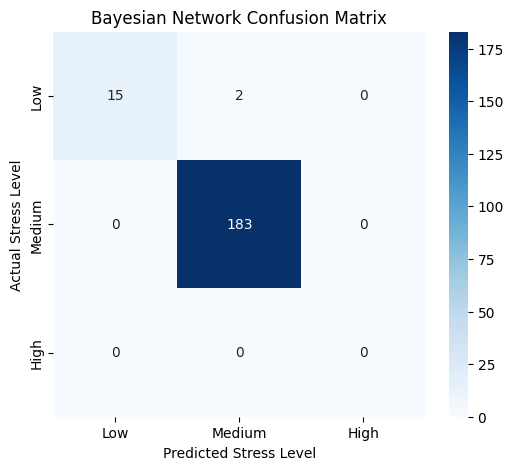

In [15]:
from sklearn.metrics import classification_report, confusion_matrix

# Initialize Inference Engine
inference = VariableElimination(model)

# Function to predict class for a given row
def predict_row(row):
    query_res = inference.map_query(
        variables=['Stress_Level'],
        evidence={'HeartRate': row['HeartRate'], 'Temperature': row['Temperature'], 'EEG_Index': row['EEG_Index']},
        show_progress=False
    )
    return query_res['Stress_Level']

# Run predictions on a sample subset for demonstration
test_sample = df_bbn.sample(n=min(200, len(df_bbn)), random_state=42)
predictions = [predict_row(row) for _, row in test_sample.iterrows()]

# Classification Report
print("--- Bayesian Belief Network Performance ---")
print(classification_report(test_sample['Stress_Level'], predictions))

# Plot Confusion Matrix
cm = confusion_matrix(test_sample['Stress_Level'], predictions, labels=['Low', 'Medium', 'High'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.xlabel('Predicted Stress Level')
plt.ylabel('Actual Stress Level')
plt.title('Bayesian Network Confusion Matrix')
plt.show()